<a href="https://colab.research.google.com/github/laurenesgarcianatalia-rgb/metodos-/blob/main/Diferenciasdivididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fórmula de las Diferencias Divididas de Newton (Algoritmo 3.2)

<span style="color:#1f77b4; font-weight:bold;">Análisis Numérico — Interpolación Polinomial</span>

## 1. Formulación del Problema
Sea $P_n(x)$ el polinomio de Lagrange de grado a lo más $n$ que interpola a una función $f$ en los nodos distintos $x_0, x_1, \dots, x_n$. Al reescribirlo en forma de Newton se obtiene:

$$P_n(x) = a_0 + a_1(x - x_0) + a_2(x - x_0)(x - x_1) + \dots + a_n(x - x_0)(x - x_1)\cdots(x - x_{n-1})$$

Evaluando sucesivamente en $x = x_0, x_1, \dots$, se deduce que los coeficientes $a_k$ corresponden a las **diferencias divididas**:

* **Diferencia dividida de orden $0$:** $f[x_i] = f(x_i)$.
* **Diferencia dividida de orden $1$:** $f[x_i, x_{i+1}] = \dfrac{f[x_{i+1}] - f[x_i]}{x_{i+1} - x_i}$.
* **Diferencia dividida de orden $k$:** $f[x_i, x_{i+1}, \dots, x_{i+k}] = \dfrac{f[x_{i+1}, \dots, x_{i+k}] - f[x_i, \dots, x_{i+k-1}]}{x_{i+k} - x_i}$.

Por lo tanto, el **polinomio interpolante de Newton** queda dado por:

$$P_n(x) = f[x_0] + \sum_{k=1}^{n} f[x_0, x_1, \dots, x_k] \prod_{i=0}^{k-1} (x - x_i)$$

**Nota:** El método de Neville es muy práctico para interpolar en un punto específico, las diferencias divididas de Newton permiten obtener y reutilizar fácilmente la expresión del polinomio interpolante.

In [1]:
import sympy as sp
import numpy as np
import pandas as pd

# 1. FÓRMULAS SIMBÓLICAS CON SYMPY (sp)
# Definimos símbolos matemáticos para mostrar las fórmulas de diferencias divididas
x, x0, x1, x2, f0, f1, f2 = sp.symbols('x x0 x1 x2 f0 f1 f2')

# Expresión simbólica de primera y segunda diferencia dividida
dif_1 = (f1 - f0) / (x1 - x0)
dif_2 = ((f2 - f1) / (x2 - x1) - (f1 - f0) / (x1 - x0)) / (x2 - x0)

print("Primera diferencia dividida simbólica:")
sp.pprint(dif_1)

print("\nSegunda diferencia dividida simbólica:")
sp.pprint(sp.simplify(dif_2))

# Ejemplo de uso de sp.diff (derivación simbólica) sobre un polinomio de prueba
pol_prueba = x**3 + 4*x**2 - 10
print("\nDerivada simbólica de ejemplo sp.diff(x**3 + 4*x**2 - 10, x):", sp.diff(pol_prueba, x))

Primera diferencia dividida simbólica:
-f₀ + f₁
────────
-x₀ + x₁

Segunda diferencia dividida simbólica:
(f₀ - f₁)⋅(x₁ - x₂) + (-f₁ + f₂)⋅(x₀ - x₁)
──────────────────────────────────────────
      (x₀ - x₁)⋅(x₀ - x₂)⋅(x₁ - x₂)       

Derivada simbólica de ejemplo sp.diff(x**3 + 4*x**2 - 10, x): 3*x**2 + 8*x


In [4]:
# 2. ALGORITMO 3.2: DIFERENCIAS DIVIDIDAS DE NEWTON
def diferencias_divididas_newton(x_nodos, y_nodos):
    # Convertimos las entradas a arreglos flotantes de NumPy
    x_arr = np.array(x_nodos, dtype=float)
    y_arr = np.array(y_nodos, dtype=float)
    n = len(x_arr) - 1  # Grado máximo del polinomio

    # matriz de tamaño (n+1) x (n+1) inicializada en ceros
    F = np.zeros((n + 1, n + 1), dtype=float)

    # Paso 1: En el algoritmo de Burden, F_{i,0} = f(x_i) para i = 0, 1, ..., n
    F[:, 0] = y_arr

    # Paso 2: Calcular diferencias divididas para i = 1..n y j = 1..i
    # En Python, range(a, b) excluye 'b', por lo que usamos n + 1 como límite superior
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (x_arr[i] - x_arr[i - j])

    # Los coeficientes del polinomio de Newton son los elementos de la diagonal F_{k,k}
    coef_newton = np.diag(F)
    return coef_newton, F


# Datos del problema (Ejemplo 1 / tabla hecha en clase)
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

coeficientes, matriz_F = diferencias_divididas_newton(x_datos, y_datos)

# tabla de diferencias divididas con pandas
cols_F = [f"Orden {j}" for j in range(len(x_datos))]
df_F = pd.DataFrame(matriz_F, columns=cols_F)
df_F.insert(0, "f(x_i)", y_datos)
df_F.insert(0, "x_i", x_datos)
df_F.index.name = "i"

# se ocultan los ceros de la triangular superior para ver solo las entradas calculadas
df_F_vis = df_F.astype(object)
for i in range(len(x_datos)):
    for j in range(i + 1, len(x_datos)):
        df_F_vis.iloc[i, j + 2] = ""

print("Tabla de diferencias divididas:")
display(df_F_vis)

print("\nCoeficientes de Newton devueltos (a_0, a_1, ..., a_n):")
for k, c in enumerate(coeficientes):
    print(f"  a_{k} = {c:.8f}")

Tabla de diferencias divididas:


,x_i,f(x_i),Orden 0,Orden 1,Orden 2,Orden 3,Orden 4
i,,,,,,,
0,1.0,0.765198,0.765198,,,,
1,1.3,0.620086,0.620086,-0.483706,,,
2,1.6,0.455402,0.455402,-0.548946,-0.108734,,
3,1.9,0.281819,0.281819,-0.578612,-0.049443,0.065878,
4,2.2,0.110362,0.110362,-0.571521,0.011818,0.068069,0.001825



Coeficientes de Newton devueltos (a_0, a_1, ..., a_n):
  a_0 = 0.76519770
  a_1 = -0.48370567
  a_2 = -0.10873389
  a_3 = 0.06587840
  a_4 = 0.00182510


Polinomio interpolante de Newton P(x):
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Polinomio expandido:
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085

Evaluación en x = 1.5: P(1.5) = 0.5118200


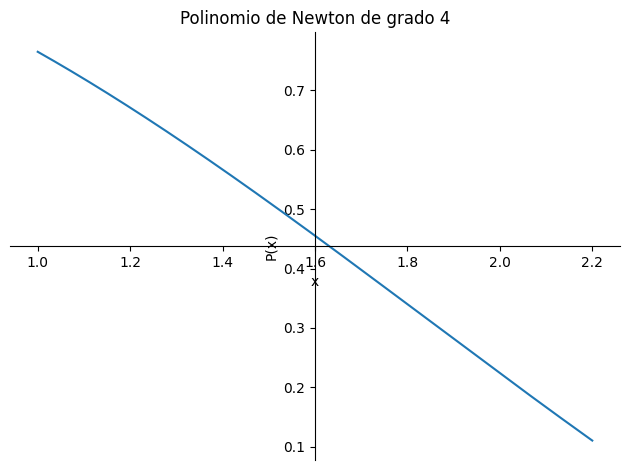

In [9]:
# 3. CONSTRUCCIÓN DEL POLINOMIO Y GRÁFICA CON SYMPY
def construir_y_graficar_newton(x_nodos, coefs, x_evaluar=None, graficar=True):

    # Variable simbólica real de SymPy
    var_x = sp.Symbol('x', real=True)

    # Construimos P_n(x) = a_0 + sum_{k=1}^n a_k * prod_{m=0}^{k-1} (x - x_m)
    pol_newton = sp.Float(coefs[0])
    producto_factores = sp.Integer(1)

    for k in range(1, len(coefs)):
        # Multiplicamos por el siguiente factor lineal (x - x_{k-1})
        producto_factores = producto_factores * (var_x - sp.Float(x_nodos[k - 1]))
        pol_newton = pol_newton + sp.Float(coefs[k]) * producto_factores

    # Versión expandida
    pol_expandido = sp.expand(pol_newton)

    print("Polinomio interpolante de Newton P(x):")
    sp.pprint(pol_newton)

    print("\nPolinomio expandido:")
    sp.pprint(pol_expandido)

    valor_eval = None
    if x_evaluar is not None:
        # Sustituimos numéricamente x en el polinomio simbólico
        valor_eval = float(pol_newton.subs(var_x, x_evaluar))
        print(f"\nEvaluación en x = {x_evaluar}: P({x_evaluar}) = {valor_eval:.7f}")

    if graficar:
        x_min, x_max = min(x_nodos), max(x_nodos)
        # Graficamos directamente con sp.plotting.plot
        sp.plotting.plot(
            pol_newton,
            (var_x, x_min, x_max),
            title=f"Polinomio de Newton de grado {len(coefs)-1}",
            xlabel="x",
            ylabel="P(x)",
            line_color="#1f77b4"
        )

    return pol_newton, valor_eval


# Punto de prueba indicado en el apunte
x_prueba = 1.5
polinomio_sym, resultado_x = construir_y_graficar_newton(x_datos, coeficientes, x_evaluar=x_prueba, graficar=True)

## 4. Solución Final

**Resultado de la prueba:** A partir de los coeficientes obtenidos con el **Algoritmo 3.2** (diferencias divididas de Newton), el polinomio interpolante de grado $4$ es:

$$P_4(x) = 0.7651977 - 0.4837057(x - 1.0) - 0.1087338(x - 1.0)(x - 1.3) + 0.0658783(x - 1.0)(x - 1.3)(x - 1.6) + 0.0018251(x - 1.0)(x - 1.3)(x - 1.6)(x - 1.9)$$

Y al evaluarlo en $x = 1.5$ se obtiene:
$$\mathbf{P_4(1.5) \approx 0.5118200}$$

**Verificación:** Al igual que en el método de Neville, la aproximación en $x = 1.5$ coincide en $0.5118200$, con la ventaja de contar con la expresión explícita del polinomio $P_4(x)$ generada y graficada simbólicamente con `sympy`[cite: 6].